###  **Anomaly Detection**

In [1]:
import plotly.io as pio
pio.renderers.default = "iframe"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sklearn.datasets import make_blobs, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from scipy.stats import zscore

### Fraud detection in e-commerce

სცენარი: ყოველდღიურად ათასობით მომხმარებელი იყენებს პლატფორმას, თუმცა ზოგიერთს სურს პროდუქცია მიიღოს გადაუხდელად – თაღლითურად.

ამოცანა: როგორ ამოიცნო მსგავსი შემთხვევები ავტომატურად, როდესაც თითოეული მომხმარებელი განსხვავებულად იქცევა?

მიდგომა:

* დაამუშაო მომხმარებელთა ქცევის ისტორია (შეკვეთის ოდენობა, დრო, მისამართი, გადახდის მეთოდი).
* იპოვო ისეთები, ვინც აშკარად განსხვავდებიან სხვა "ნორმალური" მომხმარებლებისგან.
* მაგალითად, ბევრი ძვირადღირებული შეკვეთა ახალ მისამართზე, ან არაბუნებრივად სწრაფი შეკვეთების სერია, შეიძლება იყოს საეჭვო.

---

### Intrusion detection for cyber security

სცენარი: ზოგჯერ ხდება ჰაკერული შეტევები.

ამოცანა: როგორ გამოავლინო სისტემაში შეჭრის მცდელობები ავტომატურად?

მიდგომა:

* აღრიცხე და დააკვირდი სისტემაში შესვლის მცდელობებს, ქსელურ აქტივობას, გამოყენებულ პროგრამებს.
* თუ რომელიმე ქცევა მკვეთრად განსხვავდება ჩვეულებრივისგან – მაგ. შესვლა ღამის საათებში უცხო მდებარეობიდან ან უცნობი პროგრამების გაშვება – ეს შეიძლება იყოს შეჭრის მცდელობა.

---

### Predictive Maintenance in the manufacturing industry

სცენარი: ქარხანაში დანადგარს აქვს სენსორები (ტემპერატურა, ვიბრაცია, ხმაური, ენერგიის ხარჯი და სხვა). ზოგჯერ დანადგარი კარგავს ფუნქციონირებას, რაც აჩერებს წარმოებას და მოითხოვს ძვირადღირებულ შეკეთებას.

ამოცანა: როგორ შეიძლება გამოვიცნოთ მწყობრიდან გამოსვლის მომენტი მანამდე, სანამ ავარია მოხდება?

მიდგომა:

* გაანალიზე სენსორებიდან შემოსული დროითი მონაცემები.
* მოძებნე ცვლილებები – მაგალითად, თუ ვიბრაცია თანდათანობით იმატებს ან ხმაურის დონე მოულოდნელად იზრდება.
* სისტემა შეიძლება განათდეს "წითლად", როდესაც ქცევა სცდება ნორმალურ დიაპაზონს, რაც მიანიშნებს მოახლოებულ დაზიანებაზე.

<img src="../../images/aws-cost-anomaly.webp" width="500">

---

| ტიპი              | წინაპირობა                                                | ალგორითმები                                                                    | კარგად მუშაობს                                        |
| --------------------- | ------------------------------------------------------------ | ---------------------------------------------------------------------------------- | ------------------------------------------------------ |
| Statistical-Based | მონაცემები ნორმალურადაა განაწილებული | - Z-Score<br>- IQR<br>- Grubbs-ის ტესტი                                            | დაბალგანზომილებიანი რიცხვითი მონაცემები                |
| Distance-Based    | Outliers შორს არიან სხვა მონაცემებისგან    | - kNN<br>- DBSCAN<br> | კლასტერიზებული ან გეომეტრიულად განთავსებული მონაცემები |
| Density-Based     | Outliers დაბალი სიმჭიდროვის რეგიონებში გვხვდებიან          | - LOF (Local Outlier Factor)| არაერთგვაროვანი სიმჭიდროვის მქონე მონაცემები           |
| Model-Based       | მოდელი გამოყოფს Outliers | - One-Class SVM<br>- Isolation Forest<br> | მაღალი განზომილებიანი მონაცემები                    |


### Z-Score:

$$z = \frac{x - \mu}{\sigma},$$

სადაც:

* $x$ - მონაცემი
* $\mu$ - საშუალო მნიშვნელობა
* $\sigma$ - სტანდარტული გადახრა

მუშაობს კარგად მხოლოდ მაშინ, როცა მონაცემები ნორმალურადაა განაწილებული.
* z = 0 - მნიშვნელობა ზუსტად საშუალოზეა
* დადებითი z - საშუალოზე მაღალი მნიშვნელობა
* უარყოფითი z - საშუალოზე დაბალი მნიშვნელობა
* რაც უფრო შორს არის z ნულიდან, მით უფრო ალბათურია რომ მონაცემი ანომალიაა

| Z-სქორის დიაპაზონი | ინტერპრეტაცია |
| ------------------ | ------------- |
| abs(z) < 2 | ნორმალური მონაცემი |
| abs(z) > 2 | მსუბუქი ანომალია   |
| abs(z) > 3 | ძლიერი ანომალია    |

#### მაგალითი სიმულირებულ მონაცემებზე

In [4]:
# 1. Simulate data with outliers
np.random.seed(42)
normal_data = np.random.normal(loc=50, scale=5, size=100)
anomalies = np.array([30, 80, 90])  # artificial outliers
data = np.concatenate([normal_data, anomalies])
df = pd.DataFrame({"value": data})
df.head()

,value
0,52.483571
1,49.308678
2,53.238443
3,57.615149
4,48.829233


In [5]:
# Compute statistics
mean = df["value"].mean()
std = df["value"].std()

z_scores = (df["value"] - mean) / std

Q1 = df["value"].quantile(0.25)
Q3 = df["value"].quantile(0.75)
IQR = Q3 - Q1

In [6]:
k = 2
df["anomaly_std"] = (df["value"] < mean - k * std) | (df["value"] > mean + k * std)
df["anomaly_zscore"] = z_scores.abs() > 2 
df["anomaly_iqr"] = (df["value"] < Q1 - 1.5 * IQR) | (df["value"] > Q3 + 1.5 * IQR)

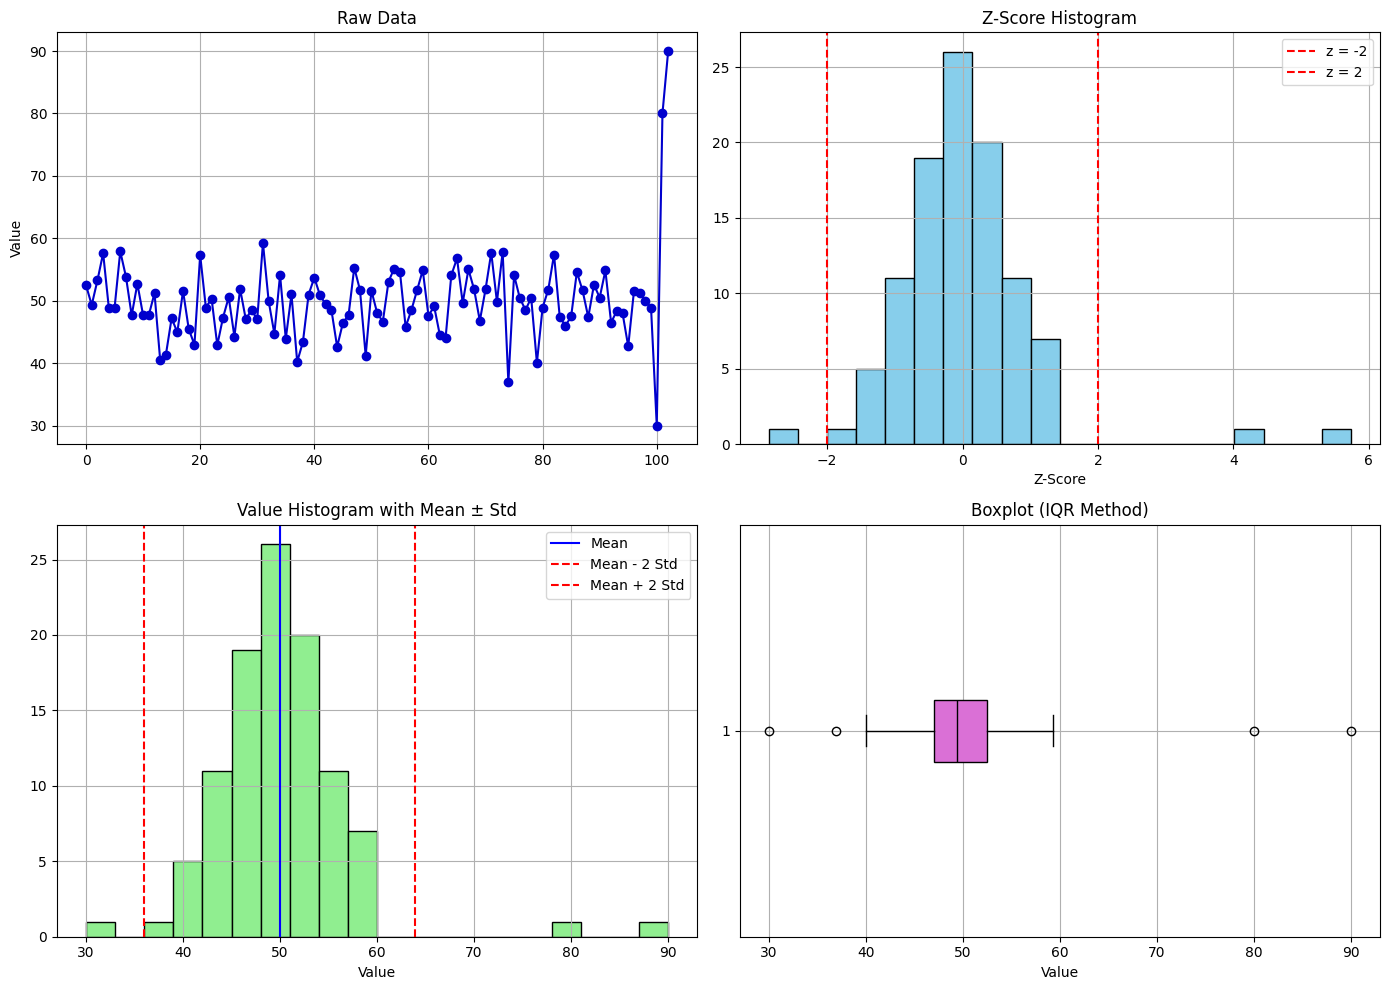

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# სიმულირებული მონაცემები
axes[0, 0].plot(df["value"], marker="o", color="mediumblue", label="Data")
axes[0, 0].set_title("Raw Data")
axes[0, 0].set_ylabel("Value")
axes[0, 0].grid(True)

# Z-score histogram
axes[0, 1].hist(z_scores, bins=20, color="skyblue", edgecolor="black")
axes[0, 1].axvline(-2, color="red", linestyle="--", label="z = -2")
axes[0, 1].axvline(2, color="red", linestyle="--", label="z = 2")
axes[0, 1].set_title("Z-Score Histogram")
axes[0, 1].set_xlabel("Z-Score")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Histogram with mean ± std
axes[1, 0].hist(df["value"], bins=20, color="lightgreen", edgecolor="black")
axes[1, 0].axvline(mean, color="blue", linestyle="-", label="Mean")
axes[1, 0].axvline(mean - 2 * std, color="red", linestyle="--", label="Mean - 2 Std")
axes[1, 0].axvline(mean + 2 * std, color="red", linestyle="--", label="Mean + 2 Std")
axes[1, 0].set_title("Value Histogram with Mean ± Std")
axes[1, 0].set_xlabel("Value")
axes[1, 0].legend()
axes[1, 0].grid(True)

# Boxplot (IQR method)
axes[1, 1].boxplot(df["value"], vert=False, patch_artist=True,
                   boxprops=dict(facecolor="orchid", color="black"),
                   medianprops=dict(color="black"),
                   whiskerprops=dict(color="black"),
                   capprops=dict(color="black"),
                   flierprops=dict(marker="o", color="red", markersize=6))
axes[1, 1].set_title("Boxplot (IQR Method)")
axes[1, 1].set_xlabel("Value")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=df.index,
    y=df["value"],
    mode="lines+markers",
    name="Data",
    line=dict(color="royalblue"),
    marker=dict(size=6)
))

fig.add_trace(go.Scatter(
    x=df[df["anomaly_std"]].index,
    y=df[df["anomaly_std"]]["value"],
    mode="markers",
    name="Mean±Std",
    marker=dict(color="red", symbol="circle", size=10)
))

fig.add_trace(go.Scatter(
    x=df[df["anomaly_zscore"]].index,
    y=df[df["anomaly_zscore"]]["value"],
    mode="markers",
    name="Z-Score",
    marker=dict(color="green", symbol="x", size=10)
))

fig.add_trace(go.Scatter(
    x=df[df["anomaly_iqr"]].index,
    y=df[df["anomaly_iqr"]]["value"],
    mode="markers",
    name="IQR",
    marker=dict(color="blue", symbol="square", size=10)
))

fig.update_layout(
    title="Anomaly Detection (Statistical Methods)",
    xaxis_title="Index",
    yaxis_title="Value",
    legend_title="Method",
    height=500,
    template="plotly_white"
)

fig.show()

### Isolation Forest

Isolation Forest ყოველი წერტილის იზოლირებას ახდენს და აკვირდება რამდენად ადვილი იყო ამ წერტილის იზოლირება. რაც უფრო ნაკლები გაყოფაა საჭირო წერტილის იზოლირებისათვის, მით უფრო ალბათურია რომ ეს წერტილი ანომალიაა. 

<img src="../../images/iforest.png" width="800">


1. მონაცემების შემთხვევითი დაყოფა:
   * აირჩიე შემთხვევითი მახასიათებელი (feature)
   * აირჩიე ამ მახასიათებლის შემთხვევითი ზღვარი
   * გაყავი მონაცემები ამ ზღვრის მიხედვით (მარცხნივ/მარჯვნივ)

2. იზოლაციის ხის აგება:
   * ასე იგება decision tree
   * პროცესი მეორდება მანამ სანამ წერტილი იზოლირებული არაა ან ხე მაქსიმალურ სიღრმეს არ მიაღწევს
   * რაც უფრო მალე მივაღწევ წერტილამდე (ანუ ნაკლები გაყოფაა საჭირო), მით უფრო მარტივად იზოლირდება ის

3. ბევრი ხის აგება:
   * იზოლაციის ტყე შედგება მრავალი ასეთი შემთხვევითი ხისგან
   * თითოეული წერტილისთვის ვთვლით საშუალო სიმაღლეს

<img src="../../images/tree.png" width="800">

---

## score:

* anomaly score გამოთვლება ეფუძნება საშუალო გზის სიგრძეს (`h(x)`) წერტილის `x` იზოლაციის ტყეში

$$
s(x) = 2^{-\frac{E(h(x))}{c(n)}}
$$

სადაც:

* $E(h(x))$ - საშუალო გზა წერტილამდე,
* $c(n)$ - ნორმალიზაციის ფაქტორი (`c(n) ≈ log(n)`),
* შედეგი \[0, 1]-ის შუალედშია:

  * თუ $s(x) \approx 1$ → ძალიან მარტივად იზოლირდება → ანომალიაა
  * თუ $s(x) \approx 0.5$ → ნორმალური მონაცემი

| პარამეტრი         | აღწერა                                   | გავლენა                                                                 | რეკომენდაცია                                        |
| ----------------- | ---------------------------------------- | ----------------------------------------------------------------------- | -------------------------------------------------------------- |
| n_estimators  | ხეების რაოდენობა (Forest-ში)             | მეტი ხე → შედეგი უფრო სტაბილური, მაგრამ ალგორითმი ნელდება               | ჩვეულებრივ 100–300 საკმარისია                              |
| contamination | მოსალოდნელი ანომალიების წილი მონაცემებში | არასწორი მნიშვნელობა → არასწორი გადაწყვეტილების ზღვარი                 | უნდა შეფასდეს წინასწარ; სხვადასხვა მნიშვნელობების მოსინჯვა, ვალიდაცია |
| max_samples   | ნიმუშების რაოდენობა თითო ხეზე            | მცირე მნიშვნელობა → უფრო სწრაფად მუშაობს და ხშირად გენერალიზაცია უკეთესად შეუძლია| სტანდარტი: `min(256, n_samples)`; უმეტესად არ ღირს გაზრდა      |


#### Wine recognition dataset

In [9]:
# მონაცემების ჩატვირთვა
wine = load_wine(as_frame=True)
df = wine.frame[["flavanoids", "malic_acid", "target"]]

# მხოლოდ 2 feature
X = df[["flavanoids", "malic_acid"]] # flavanoids - გემოსა და ფერის ინტენსივობა, malic_acid - მჟავიანობის მაჩვენებელი
df.head()

,flavanoids,malic_acid,target
0,3.06,1.71,0
1,2.76,1.78,0
2,3.24,2.36,0
3,3.49,1.95,0
4,2.69,2.59,0


In [14]:
# Isolation Forest
model = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)

df["outlier"] = model.fit_predict(X)
df["score"] = model.decision_function(X)

In [15]:
# რამდენი outlier ვიპოვეთ
df["outlier"].value_counts()

outlier
 1    176
-1      2
Name: count, dtype: int64

decision_function გვაძლევს score-ს, რამდენად ნორმალურია მონაცემი.
რაც უფრო მაღალია score, მით მეტი გაყოფა დასჭირდა decision-tree ალგორითმს წერტილის იზოლაციისთვის.
შესაბამისად, outlier წერტილებს აქვთ დაბალი score, ხოლო ნორმალურებს - მაღალი.

მნიშვნელობები ძირითადად მოთავსებულია [-0.2, 0.3] შუალედში.
$$
\text{decision\_function}(x) = \frac{E(h(x))}{c(n)} - 1
$$

* `decision_function(x) > 0` → normal
* `decision_function(x) < 0` → anomaly

In [16]:
# ყველაზე ანომალიური წერტილები
df.sort_values("score").head()

,flavanoids,malic_acid,target,outlier,score
121,5.08,2.05,1,-1,-0.083221
123,2.65,5.80,1,-1,-0.055109
146,0.34,5.04,2,1,0.016461
173,0.61,5.65,2,1,0.048738
137,0.60,5.51,2,1,0.063967


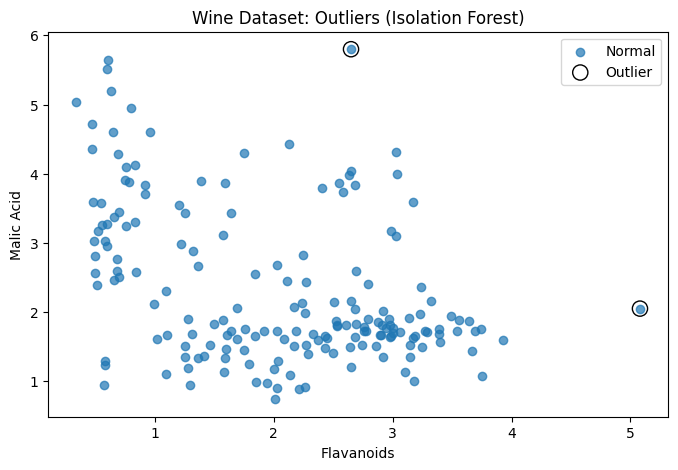

In [17]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df["flavanoids"], df["malic_acid"], alpha=0.7, label="Normal")

outliers = df[df["outlier"] == -1]
plt.scatter(outliers["flavanoids"],outliers["malic_acid"],facecolors="none", edgecolors="black", s=120, label="Outlier")

plt.xlabel("Flavanoids")
plt.ylabel("Malic Acid")
plt.title("Wine Dataset: Outliers (Isolation Forest)")
plt.legend()
plt.show()

#### Time Series example

In [14]:
# სინთეტიკური მონაცემები
np.random.seed(42)
time = pd.date_range(start="2022-01-01", periods=200, freq="D")
values = np.sin(np.linspace(0, 20, 200)) + np.random.normal(0, 0.3, size=200)

# Add some anomalies
values[50] += 5
values[120] -= 4
values[180] += 6

df = pd.DataFrame({"Time": time, "Value": values})
df.set_index("Time", inplace=True)
df.head()

,Value
Time,
2022-01-01,0.149014
2022-01-02,0.058854
2022-01-03,0.393961
2022-01-04,0.753869
2022-01-05,0.321023


In [15]:
# გავწვრთნათ მოდელი
model = IsolationForest(contamination=0.015, random_state=42) # contamination მიუთითებს, მონაცემების რამდენი პროცენტია outlier
df["anomaly_if"] = model.fit_predict(df[["Value"]])
df["anomaly_if"] = df["anomaly_if"] == -1

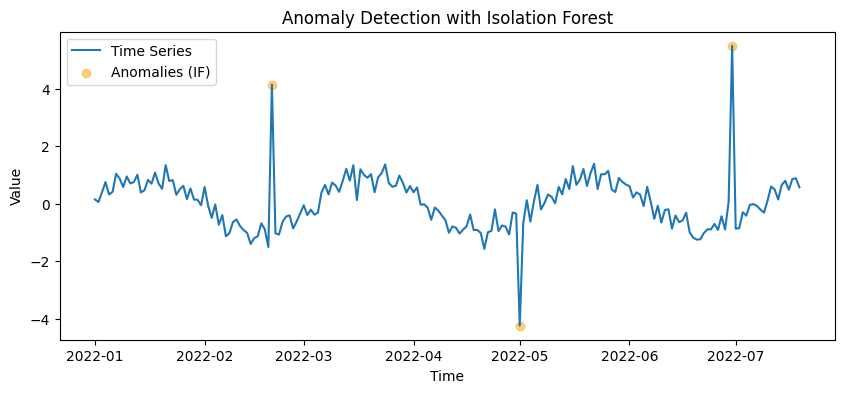

In [16]:
# Plot anomalies
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["Value"], label="Time Series")
plt.scatter(df.index[df["anomaly_if"]], df["Value"][df["anomaly_if"]], color="orange", label="Anomalies (IF)", alpha=0.5)
plt.title("Anomaly Detection with Isolation Forest")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()

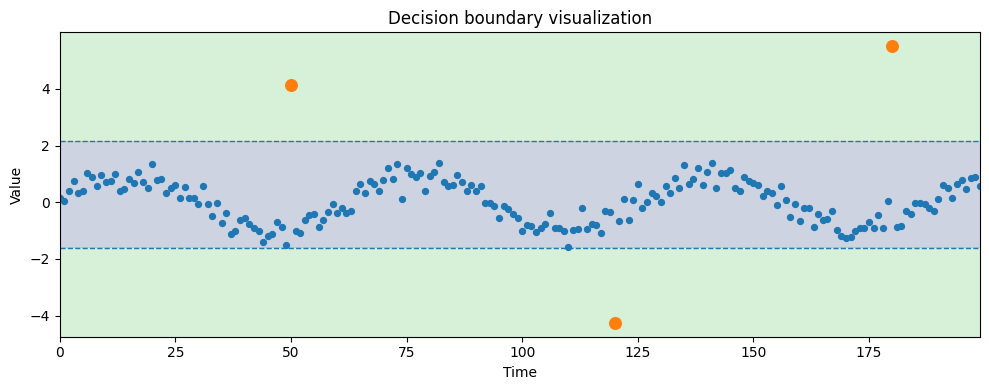

In [17]:
# Decision Boundary
vmin, vmax = df["Value"].min(), df["Value"].max()
v_grid = np.linspace(vmin - 0.5, vmax + 0.5, 2000).reshape(-1, 1)

pred_grid = model.predict(v_grid)

# boundary points = where prediction changes normal <-> anomaly
change_idx = np.where(np.diff(pred_grid) != 0)[0]
boundary_values = v_grid[change_idx].ravel() 

t_num = (df.index - df.index[0]).days.values.astype(float)

t_grid = np.linspace(t_num.min(), t_num.max(), 400)
v_grid2 = np.linspace(vmin - 0.5, vmax + 0.5, 400)
TT, VV = np.meshgrid(t_grid, v_grid2)

bg_pred = model.predict(VV.reshape(-1, 1)).reshape(VV.shape)
bg = (bg_pred == -1).astype(int)  # 1=anomaly region, 0=normal region

fig2, ax2 = plt.subplots(figsize=(10, 4))
ax2.contourf(TT, VV, bg, alpha=0.25, levels=[-0.5, 0.5, 1.5])
ax2.scatter(t_num, df["Value"], s=18)
ax2.scatter(t_num[df["anomaly_if"]],
            df.loc[df["anomaly_if"], "Value"],
            s=70)

# draw boundary lines on Value
for bv in boundary_values:
    ax2.axhline(bv, linestyle="--", linewidth=1)

ax2.set_title("Decision boundary visualization")
ax2.set_xlabel("Time")
ax2.set_ylabel("Value")
fig2.tight_layout()
plt.show()

decision_function გვაძლევს score-ს, რამდენად ნორმალურია მონაცემი.
რაც უფრო მაღალია score, მით მეტი გაყოფა დასჭირდა decision-tree ალგორითმს წერტილის იზოლაციისთვის.

In [18]:
normality_scores = model.decision_function(df[["Value"]])
df["scores"] = normality_scores.round(2)
df.sort_values(by="scores").head()

,Value,anomaly_if,scores
Time,,,
2022-05-01,-4.247433,True,-0.19
2022-06-30,5.499429,True,-0.16
2022-02-20,4.145730,True,-0.13
2022-04-21,-1.573850,False,0.00
2022-02-19,-1.506475,False,0.05


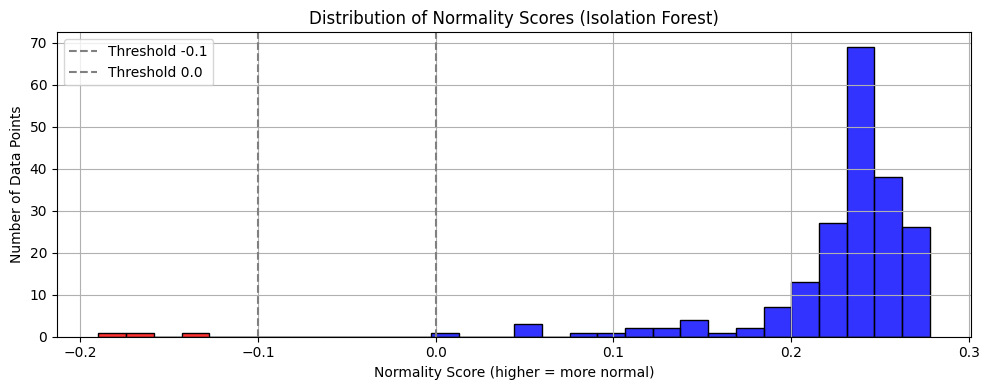

In [19]:
# როგორც გრაფიკიდან ჩანს, ნორმალური წერტილები უფრო ხშირად გვხვდება, ვიდრე outliers
score_labels = pd.cut(
    normality_scores,
    bins=[-np.inf, -0.1, 0.0, np.inf],
    labels=["anomalous", "borderline", "normal"]
)

# DataFrame for visualization
df_plot = pd.DataFrame({
    "score": normality_scores,
    "Category": score_labels
})

# Plot
plt.figure(figsize=(10, 4))
sns.histplot(data=df_plot, x="score", hue="Category", bins=30, palette={
    "anomalous": "red", "borderline": "orange", "normal": "blue"
}, alpha=0.8)

plt.axvline(x=-0.1, color="gray", linestyle="--", label="Threshold -0.1")
plt.axvline(x=0.0, color="gray", linestyle="--", label="Threshold 0.0")
plt.title("Distribution of Normality Scores (Isolation Forest)")
plt.xlabel("Normality Score (higher = more normal)")
plt.ylabel("Number of Data Points")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Local Outlier Factor (LOF)

* გვაქვს წერტილი A და B.

  * $dist(A, B)$ = პირდაპირი ევკლიდური მანძილი A-დან B-მდე
  * $k-dist(B)$ = მანძილი B-დან თავის k უახლოეს მეზობელთან

<img src="../../images/reach_dist.webp" width="300">

LOF არის სიმჭიდროვეზე დაფუძნებული outlier detection ალგორითმი, რომელიც აფასებს, რამდენად მჭიდროდ მდებარეობს წერტილი საკუთარი მეზობლების ფონზე.

LOF შედარებას აკეთებს:

* წერტილის ლოკალური სიმკვრივე
* მეზობლების სიმკვრივე

წერტილი ითვლება ანომალიად, თუ მისი სიმკვრივე ბევრად დაბალია მეზობლების სიმკვრივესთან შედარებით.

---

#### 1. k-დისტანცია

* გამოთვალეთ კონკრეტული წერტილიდან მანძილი მის $k$-უახლოეს მეზობლამდე.

#### 2. Reachability Distance

* ორ წერტილს შორის A და B:

$$
\text{reach-dist}_k(A, B) = \max(\text{k-dist}(B), \text{dist}(A, B))
$$

→ უზრუნველყოფს, რომ ძალიან ახლოს მდებარე წერტილებისთვის ძალიან პატარა მანძილები არ გვქონდეს.

#### 3. Local Reachability Density, LRD

* ლოკალური მიღწევადობის სიმჭიდროვე არის $k$-უახლოეს მეზობელამდე Reachability Distance-ის არითმეტიკული საშუალოს შებრუნებული:

$$
\text{LRD}(A) = \frac{1}{\text{mean reach-dist}}
$$

#### 4. LOF-score

* ამცირებს, რამდენად განსხვავდება A-ს სიმჭიდროვე მისი მეზობლების საშუალო სიმჭიდროვისგან:

$$
\text{LOF}_k(A) = \frac{\text{მეზობლების საშუალო LRD}}{\text{LRD(A)}}
$$

* LOF ≈ 1 → ნორმალური წერტილი
* LOF > 1.5 → შესაძლო outlier
* LOF ≫ 1.5 → ძლიერი outlier

In [100]:
# სინთეტიკური მონაცემები
X1, _ = make_blobs(n_samples=150, centers=[[0, 0]], cluster_std=0.3, random_state=42)   # dense cluster
X2, _ = make_blobs(n_samples=150, centers=[[5, 5]], cluster_std=1.0, random_state=42)   # sparse cluster
X_outliers = np.random.uniform(low=-2, high=8, size=(15, 2))                            # random outliers
X = np.vstack((X1, X2, X_outliers))

ძირითადი პარამეტრები:
* n_neighbors: მეზობლების რაოდენობა (საუკეთესო მნიშვნელობა დამოკიდებულია მონაცემებზე)
    - რეკომენდაცია: `n_neighbors`$=\sqrt{N},$ სადაც `N` არის მონაცემთა რაოდენობა
* contamination: მონაცემებში მოსალოდნელი ანომალიების პროცენტი

In [101]:
# Apply Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=10, contamination=0.05)
y_pred = lof.fit_predict(X)
lof_scores = -lof.negative_outlier_factor_

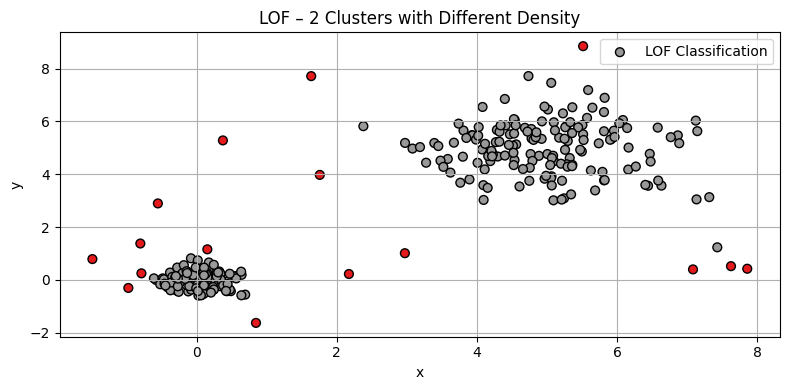

In [102]:
# Plot the results
plt.figure(figsize=(8, 4))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="Set1", s=40, edgecolor="k", label="LOF Classification")
plt.title("LOF – 2 Clusters with Different Density")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [103]:
# y_pred = 1 → ნორმალური მონაცემი
# y_pred = -1 → ანომალია
pd.Series(y_pred).value_counts()

 1    299
-1     16
Name: count, dtype: int64

In [104]:
q95 = np.percentile(lof_scores, 95)
pd.Series(lof_scores > q95).value_counts()

False    299
True      16
Name: count, dtype: int64

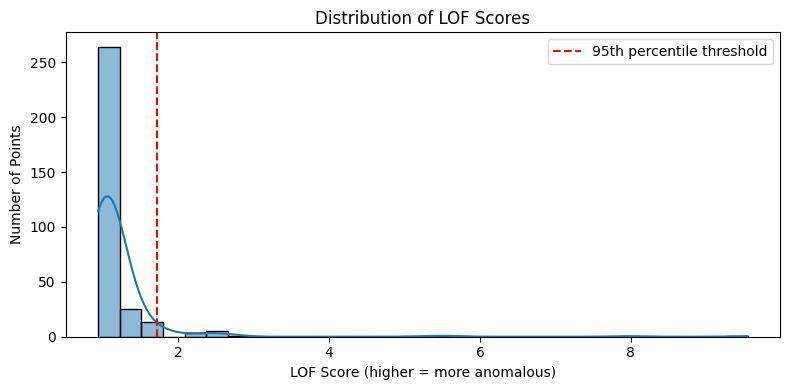

In [25]:
# Score LOF ≈ 1 → ნორმალური წერტილი, LOF > 1.5 → შესაძლო outlier, LOF ≫ 1.5 → ძლიერი outlier
plt.figure(figsize=(8, 4))
sns.histplot(lof_scores, bins=30, kde=True)
plt.axvline(q95, color="red", linestyle="--", label="95th percentile threshold")
plt.title("Distribution of LOF Scores")
plt.xlabel("LOF Score (higher = more anomalous)")
plt.ylabel("Number of Points")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# Nearest Neighbors დაგვჭირდება Local Reachability Density-თვის
k = 10
nbrs = NearestNeighbors(n_neighbors=k).fit(X)
distances, indices = nbrs.kneighbors(X)

# k-distance თითოეული წერტილისთვის
k_distances = distances[:, -1]

# reachability distances
reachability_distances = np.maximum(distances, k_distances[indices.flatten()].reshape(distances.shape))

# Local Reachability Density (LRD)
lrd = 1. / (np.mean(reachability_distances, axis=1))

* თუ წერტილი მდებარეობს მჭიდროდ თავის მეზობლებთან, LRD მაღალია

* თუ წერტილი შორისოა მეზობლებისგან, LRD დაბალია

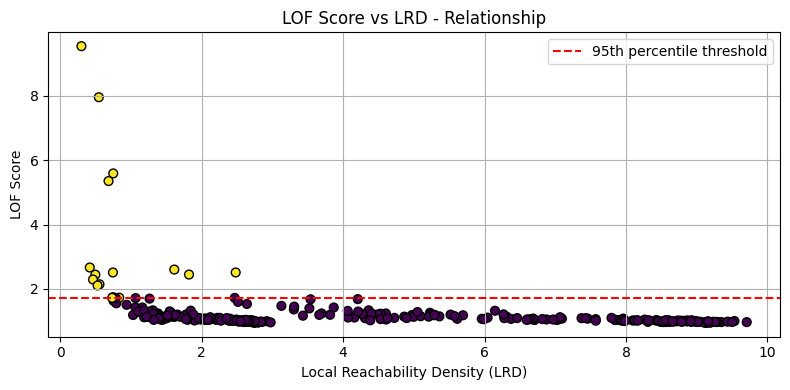

In [27]:
# LRD vs LOF Score
plt.figure(figsize=(8, 4))
plt.scatter(lrd, lof_scores, c=(y_pred == -1), edgecolor="k", s=40)
plt.axhline(q95, color="red", linestyle="--", label="95th percentile threshold")
plt.xlabel("Local Reachability Density (LRD)")
plt.ylabel("LOF Score")
plt.title("LOF Score vs LRD - Relationship")
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

### One-Class Support Vector Machine

One-Class SVM არის unsupervised Learning ალგორითმი, რომლის მიზანია იპოვოს ფუნქცია $f(x)$, რომელიც დადებითია ნორმალური წერტილებისთვის და უარყოფითი ანომალიებისთვის.

One-Class SVM კარგი არჩევანია, როდესაც გვაქვს მხოლოდ ნორმალური მონაცემები ან ანომალიები ძალიან ცოტაა.

| პარამეტრი | ეფექტი                             | რეკომენდაცია                                                     |
| --------- | ---------------------------------- | ---------------------------------------------------------------- |
| `nu`      | რამდენ პროცენტს აღიქვამს ანომალიად| 0.01–0.1 უმეტეს შემთხვევაში       |
| `gamma`   | decision boundary-ის მოქნილობა| 2D–3D: 0.1–1, მაღალი განზომილება: 0.01–0.1 |

* დიდი `gamma` → decision boundary ნორმალური მონაცემის გარშემო უფრო “tight”
* Small dataset → შეგიძლიათ შეარჩიოთ `gamma` მაღალი, `nu` პატარა 
* ძალიან არარეგულარული მონაცემები / outliers → `nu` უფრო მაღალი, `gamma` მცირე
* `nu`-ს შერჩევა: თუ არ იცით ანომალიების პროცენტი, შეიძლება ექსპერიმენტით შერჩეული იყოს 0.05–0.1, ხოლო შემდეგ ნახოთ როგორ განაწილდება decision_function score–ები.
* `gamma`-ს შერჩევა: შეგიძლიათ გამოიყენოთ `gamma='scale'` ან `gamma='auto'`:
    * `scale` = 1 / (n_features * X.var())
    * `auto` = 1 / n_features

In [28]:
# სინთეტიკური მონაცემები
X_inliers, _ = make_blobs(n_samples=200, centers=[[0, 0]], cluster_std=0.5, random_state=42)

X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X = np.vstack((X_inliers, X_outliers))

In [29]:
# One-Class SVM
svm = OneClassSVM(kernel="rbf", gamma=0.1, nu=0.1) 
y_pred = svm.fit_predict(X)  # -1 = ანომალია, 1 = ნორმალური
scores = svm.decision_function(X)  # რაც მაღალია, მით უფრო ნორმალურია

In [30]:
pd.Series(y_pred).value_counts()

 1    199
-1     21
Name: count, dtype: int64

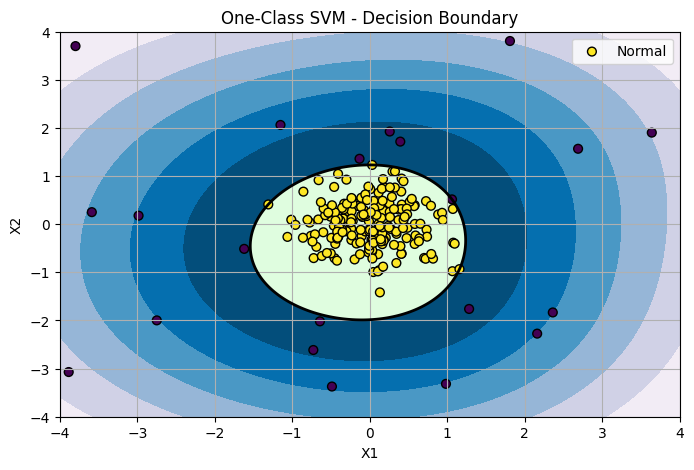

In [31]:
# Decision boundary და grid
xx, yy = np.meshgrid(np.linspace(-4, 4, 500), np.linspace(-4, 4, 500))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.title("One-Class SVM - Decision Boundary")

# Decision boundary
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors="black")  # ზღვარი
plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 7), cmap=plt.cm.PuBu)  # არ ნორმალური ზონა
plt.contourf(xx, yy, Z, levels=[0, Z.max()], colors="palegreen", alpha=0.3)  # ნორმალური ზონა

# მონაცემების scatter
plt.scatter(X[:, 0], X[:, 1], c=y_pred, edgecolor="k", s=40, label="Normal")

plt.xlabel("X1")
plt.ylabel("X2")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
pd.Series(scores < 0).value_counts()

False    199
True      21
Name: count, dtype: int64

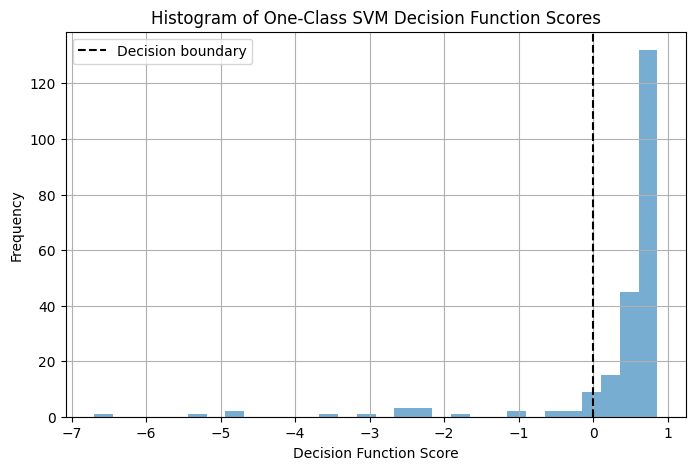

In [33]:
# score > 0 - მონაცემი decision boundary-ს შიგნითაა → ნორმალური მონაცემი
# score < 0 - მონაცემი decision boundary-ს გარეთაა → ანომალია
plt.figure(figsize=(8, 5))
plt.hist(scores, bins=30, alpha=0.6)
plt.axvline(x=0, color="black", linestyle="--", label="Decision boundary")
plt.xlabel("Decision Function Score")
plt.ylabel("Frequency")
plt.title("Histogram of One-Class SVM Decision Function Scores")
plt.legend()
plt.grid(True)
plt.show()

### DBSCAN

In [34]:
# DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X)

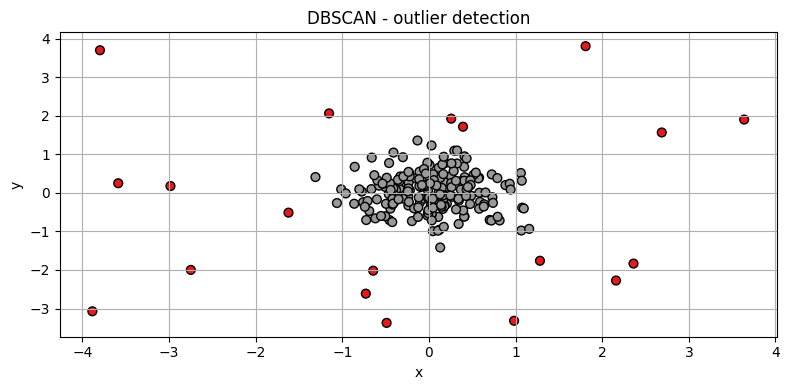

In [35]:
# -1 ნიშნავს ანომალიას
plt.figure(figsize=(8, 4))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="Set1", s=40, edgecolor="k")
plt.title("DBSCAN - outlier detection")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.tight_layout()
plt.show()

### სხვადასხვა მოდელების შედარება

In [105]:
# სინთეტიკური მონაცემების შექმნა
np.random.seed(42)
X_normal = np.random.normal(loc=0, scale=1, size=(100, 2))
X_anomalies = np.random.uniform(low=-6, high=6, size=(10, 2))
X = np.vstack([X_normal, X_anomalies])
y_true = np.array([0]*100 + [1]*10)

df = pd.DataFrame(X, columns=["x1", "x2"])
df["label"] = y_true

In [106]:
# StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["x1", "x2"]])

In [110]:
results = {}

# 1. Z-Score
z_scores = np.abs(zscore(X_scaled))
results["Z-Score"] = (z_scores > 2).any(axis=1).astype(int)

# 2. IQR
q1 = np.percentile(X_scaled, 25, axis=0)
q3 = np.percentile(X_scaled, 75, axis=0)
iqr_range = q3 - q1
outlier_mask = ((X_scaled < (q1 - 1.5 * iqr_range)) | (X_scaled > (q3 + 1.5 * iqr_range))).any(axis=1)
results["IQR"] = outlier_mask.astype(int)

# 3. Isolation Forest
iso = IsolationForest(contamination=0.1, random_state=42)
results["Isolation Forest"] = (iso.fit_predict(X_scaled) == -1).astype(int)

# 4. LOF
lof = LocalOutlierFactor(n_neighbors=10, contamination=0.1)
results["LOF"] = (lof.fit_predict(X_scaled) == -1).astype(int)

# 5. One-Class SVM
svm = OneClassSVM(kernel="rbf", gamma=0.1, nu=0.1)
results["One-Class SVM"] = (svm.fit_predict(X_scaled) == -1).astype(int)

# 6. DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=3)
results["DBSCAN"] =  (dbscan.fit_predict(X_scaled) == -1).astype(int)

# შედეგები ერთად შევინახოთ
for key, val in results.items():
    df[key] = val

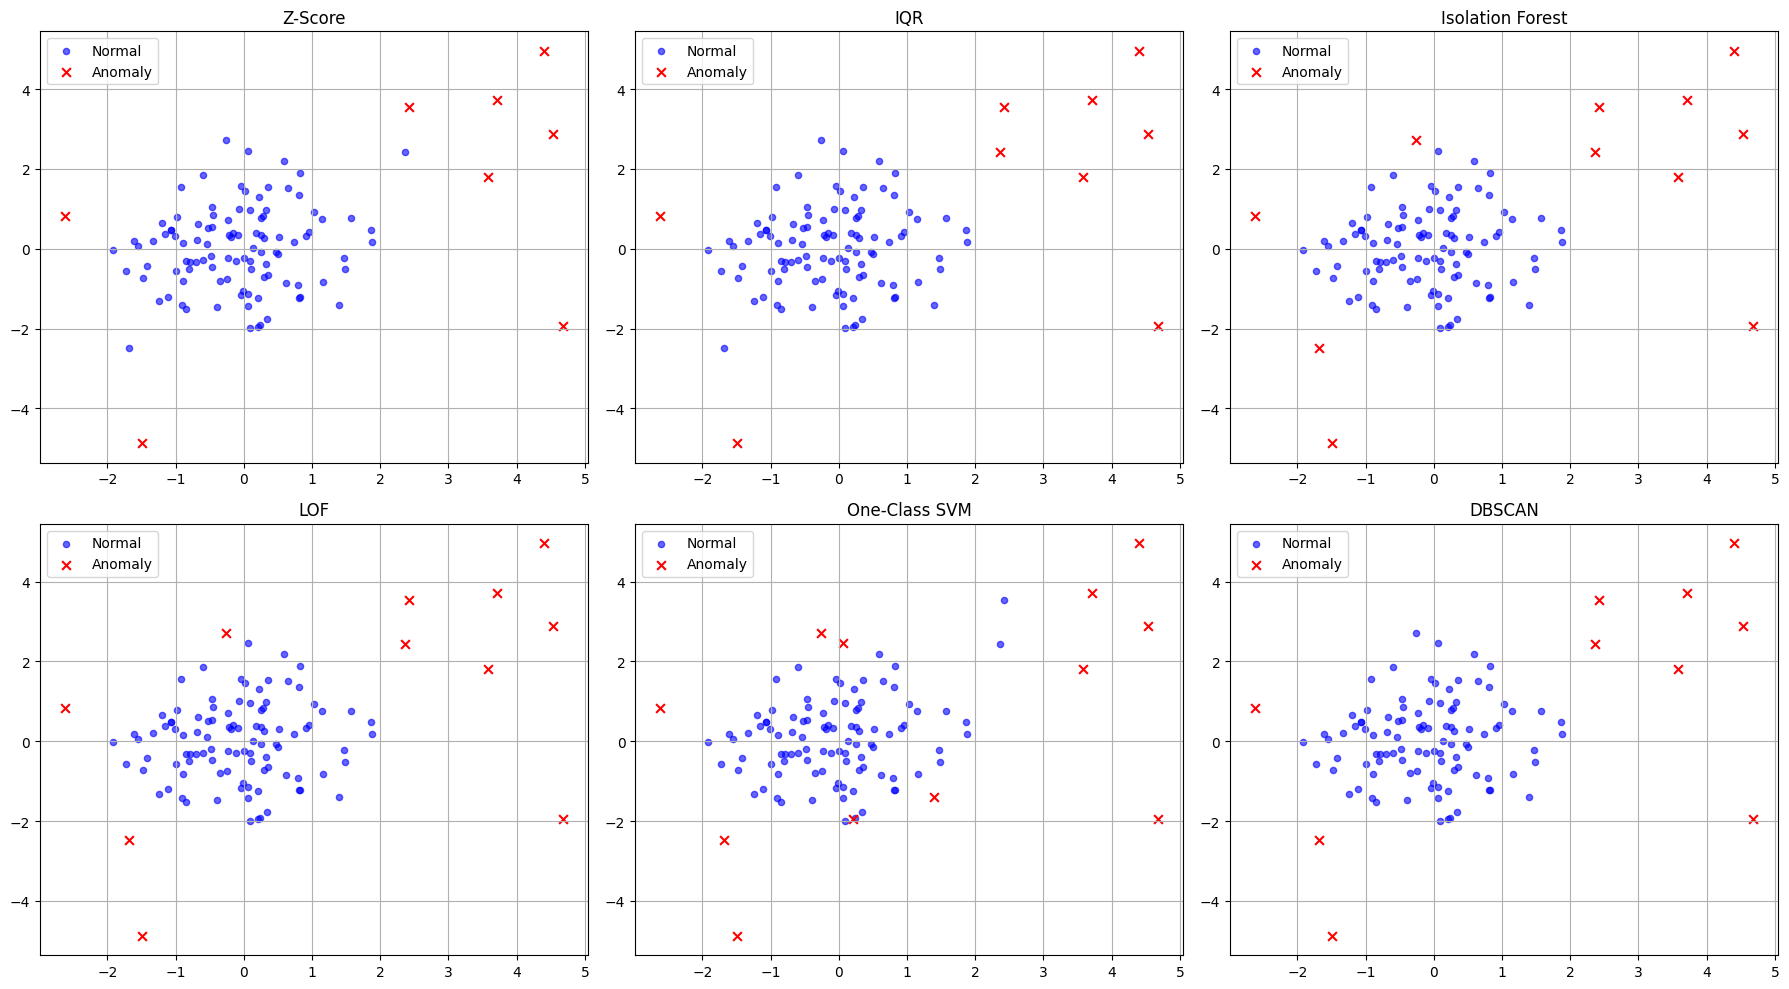

In [111]:
methods = list(results.keys())
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, method in enumerate(methods):
    ax = axes[idx]
    normal = df[df[method] == 0]
    anomaly = df[df[method] == 1]
    
    ax.scatter(normal["x1"], normal["x2"], c="blue", s=20, label="Normal", alpha=0.6)
    ax.scatter(anomaly["x1"], anomaly["x2"], c="red", s=40, label="Anomaly", marker="x")
    ax.set_title(method)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

| მეთოდი           | გამოყენების სცენარი                                      | უპირატესობები                                                | შეზღუდვები                                                                    | StandardScaler საჭიროება |
| ---------------- | -------------------------------------------------------- | ------------------------------------------------------------ | ----------------------------------------------------------------------------- | ------------------------ |
| Z-Score          | მარტივი, პატარა, ნორმალურად განაწილებული მონაცემები      | სწრაფი და მარტივი,<br>პარამეტრების გარეშე მუშაობს            | ეფექტური მხოლოდ ნორმალურ განაწილებაზე,<br>მგრძნობიარე თვითონ ანომალიებზე      | -|
| IQR              | სტატისტიკური გამოკვლევა                                  | მყარია ანომალიების მიმართ<br>ინტერპრეტაცია მარტივია          | მხოლოდ ერთ მახასიათებელზე მუშაობს,<br>არ ვარგა მაღალი განზომილებისთვის        | -                      |
| One-Class SVM    | ნორმალური მონაცემები <br> არაწრფივი  სტრუქტურა           | შეუძლია რთული ფორმების სწავლა                                | მგრძნობიარეა `nu` და `gamma`-ზე                                               | ✓                       |
| DBSCAN           | გეოსივრცული/გეომეტრიული მონაცემები                       | პოულობს არარეგულარული ფორმის კლასტერს<br>არ სჭირდება `k`     | მგრძნობიარეა `eps` და `min_samples`-ზე<br>ცუდად მუშაობს ცვალებად სიმჭიდროვეზე | ✓                       |
| Isolation Forest | მაღალი განზომილება<br>დიდი მონაცემები                    | მყარია ანომალიების მიმართ<br>არ საჭიროებს განაწილების ცოდნას | შეიძლება არასწორი ზღვარი გაიყვანოს                                            | -                      |
| LOF              | ლოკალური სიმჭიდროვის სხვაობები<br>არათანაბარი განაწილება | პოულობს ლოკალურ ანომალიებს,<br>დაფუძნებულია სიმჭიდროვეზე     | მგრძნობიარეა `k`-ის არჩევაზე                                                  | ✓                      |